In [4]:
import os

os.environ.setdefault(
    "CUBLAS_WORKSPACE_CONFIG",
    ":4096:8"
)

from pathlib import Path
from datetime import datetime

import sys
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch

from PIL import Image

In [5]:
PROJECT_DIR = Path(
    r"C:\Users\Joseph (YO)\JGM\U\Semestre_10\InteligenciaArtificial\Proyecto_Yuca"
)

DATASET_DIR = (
    PROJECT_DIR / "dataset" / "raw"
    / "cassava_dataset"
)

CONFIGS_DIR = PROJECT_DIR / "configs"
REPORTS_DIR = PROJECT_DIR / "reports"
MODELS_DIR = PROJECT_DIR / "models"
EXPERIMENTS_DIR = PROJECT_DIR / "experiments"

RUN_ID = "ensemble_cached_v1"

ENSEMBLE_REPORTS_DIR = (
    REPORTS_DIR / "ensemble" / RUN_ID
)

ENSEMBLE_EXPERIMENTS_DIR = (
    EXPERIMENTS_DIR / "ensemble" / RUN_ID
)

TEST_CACHE_DIR = (
    PROJECT_DIR / "dataset"
    / "cache" / "test_features_v1"
)

for directory in [

    ENSEMBLE_REPORTS_DIR,

    ENSEMBLE_EXPERIMENTS_DIR,

    TEST_CACHE_DIR

]:

    directory.mkdir(

        parents=True,

        exist_ok=True

    )

if str(PROJECT_DIR) not in sys.path:

    sys.path.insert(0, str(PROJECT_DIR))

In [6]:
from src.utils import (
    set_seed,
    get_device
)

from src.experiments import save_json

from src.feature_cache import (
    FEATURE_DIMS,
    calculate_sha256,
    dataframe_fingerprint,
    release_memory
)

from src.dataset import CassavaDataset

from src.data_generator import create_dataloader

from src.preprocessing import build_transforms

from src.ensemble import (
    soft_voting,
    validate_probabilities,
    predict_cached_probabilities,
    evaluate_probabilities,
    load_saved_probabilities
)

from src.inference import (
    read_json,
    load_shared_architecture,
    extract_batch_features,
    CassavaInferenceEngine
)

In [7]:
dataset_config = read_json(
    CONFIGS_DIR / "dataset_config.json"
)

training_config = read_json(
    CONFIGS_DIR / "training_config.json"
)

final_config = read_json(
    CONFIGS_DIR / "final_training_config.json"
)

ensemble_config = read_json(
    CONFIGS_DIR / "ensemble_config.json"
)

centralized_registry = read_json(
    CONFIGS_DIR / "centralized_model_registry.json"
)

federated_registry = read_json(
    CONFIGS_DIR / "federated_model_registry.json"
)

SEED = dataset_config["seed"]

CLASS_MAPPING = dataset_config["class_mapping"]

NUM_CLASSES = len(CLASS_MAPPING)

ARCHITECTURES = ensemble_config["architectures"]

DEVICE = get_device()

set_seed(SEED)

assert NUM_CLASSES == 5

assert len(ARCHITECTURES) == 5

assert ensemble_config["class_mapping"] == (
    CLASS_MAPPING
)

assert ensemble_config["evaluation_split"] == (
    "test"
)

assert not ensemble_config[
    "optimize_ensemble_weights"
]

assert np.isclose(

    sum(ensemble_config["weights"].values()),

    1.0

)

print("Device:", DEVICE)
print("Architectures:", ARCHITECTURES)

display(CLASS_MAPPING)

Device: cuda
Architectures: ['mobilenet_v3_large', 'efficientnet_b0', 'resnet50', 'vit_b_16', 'swin_t']


{'bacterial_blight': 0,
 'brown_streak_disease': 1,
 'green_mottle': 2,
 'healthy': 3,
 'mosaic_disease': 4}

In [8]:
final_summary = read_json(

    EXPERIMENTS_DIR

    / "final"

    / "final_cached_v1"

    / "final_training_summary.json"

)

federated_summary = read_json(

    EXPERIMENTS_DIR

    / "federated"

    / "federated_cached_v1"

    / "federated_training_summary.json"

)

assert final_summary["status"] == "completed"

assert federated_summary["status"] == "completed"

assert final_summary["models_verified"] == 5

assert federated_summary["models_verified"] == 5

assert not final_summary["test_used"]

assert not federated_summary["test_used"]

assert set(centralized_registry["models"]) == (

    set(ARCHITECTURES)

)

assert set(federated_registry["models"]) == (

    set(ARCHITECTURES)

)

print("Fase 2 verificada.")
print("Fase 3 verificada.")
print("Modelos disponibles: 10")

Fase 2 verificada.
Fase 3 verificada.
Modelos disponibles: 10


In [9]:
checkpoint_verification = []

for approach, registry in [

    ("centralized", centralized_registry),

    ("federated", federated_registry)

]:

    for model_name in ARCHITECTURES:

        model_path = (

            PROJECT_DIR

            / registry["models"][model_name][
                "model_path"
            ]

        )

        classifier_path = (

            PROJECT_DIR

            / registry["models"][model_name][
                "classifier_path"
            ]

        )

        assert model_path.exists()

        assert classifier_path.exists()

        checkpoint_verification.append({

            "architecture": model_name,

            "approach": approach,

            "model_size_mib": (

                model_path.stat().st_size / 1024**2

            ),

            "classifier_size_mib": (

                classifier_path.stat().st_size

                / 1024**2

            ),

            "model_sha256": calculate_sha256(
                model_path
            ),

            "classifier_sha256": calculate_sha256(
                classifier_path
            ),

            "valid": True

        })

df_checkpoint_verification = pd.DataFrame(

    checkpoint_verification

)

display(

    df_checkpoint_verification.drop(

        columns=[

            "model_sha256",

            "classifier_sha256"

        ]

    ).round(4)

)

df_checkpoint_verification.to_csv(

    ENSEMBLE_REPORTS_DIR

    / "checkpoint_verification.csv",

    index=False,

    encoding="utf-8-sig"

)

,architecture,approach,model_size_mib,classifier_size_mib,valid
0,mobilenet_v3_large,centralized,16.2376,4.7203,True
1,efficientnet_b0,centralized,15.5797,0.0274,True
2,resnet50,centralized,90.0114,0.0420,True
3,vit_b_16,centralized,327.3596,0.0176,True
4,swin_t,centralized,105.2678,0.0176,True
5,mobilenet_v3_large,federated,16.2389,4.7204,True
6,efficientnet_b0,federated,15.5812,0.0275,True
7,resnet50,federated,90.0127,0.0421,True
8,vit_b_16,federated,327.3603,0.0177,True
9,swin_t,federated,105.2687,0.0177,True


In [10]:
df_splits = pd.read_csv(

    REPORTS_DIR / "dataset_splits.csv"

)

df_development = df_splits[

    df_splits["split"] == "development"

].reset_index(drop=True)

df_test = df_splits[

    df_splits["split"] == "test"

].reset_index(drop=True)

assert len(df_development) == 18187

assert len(df_test) == 3210

assert df_test["filepath"].is_unique

assert df_test["sha256"].notna().all()

assert df_development["sha256"].notna().all()

assert set(

    df_development["sha256"]

).isdisjoint(

    df_test["sha256"]

)

assert (df_test["fold"] == -1).all()

assert set(df_test["class"]) == (

    set(CLASS_MAPPING)

)

print("Test independiente:", len(df_test))

display(

    df_test["class"].value_counts()

)

Test independiente: 3210


class
mosaic_disease          1974
healthy                  387
green_mottle             358
brown_streak_disease     328
bacterial_blight         163
Name: count, dtype: int64

In [11]:
df_test_distribution = (

    df_test["class"]

    .value_counts()

    .rename_axis("class")

    .reset_index(name="images")

)

df_test_distribution["percentage"] = (

    df_test_distribution["images"]

    / len(df_test)

    * 100

)

display(df_test_distribution.round(2))

df_test_distribution.to_csv(

    ENSEMBLE_REPORTS_DIR

    / "test_distribution.csv",

    index=False,

    encoding="utf-8-sig"

)

,class,images,percentage
0,mosaic_disease,1974,61.50
1,healthy,387,12.06
2,green_mottle,358,11.15
3,brown_streak_disease,328,10.22
4,bacterial_blight,163,5.08


In [12]:
development_cache_dir = (

    PROJECT_DIR

    / final_config["feature_cache_dir"]

)

mixed_precision_by_model = {}

development_cache_hashes = {}

for model_name in ARCHITECTURES:

    cache_path = (

        development_cache_dir

        / f"{model_name}.pth"

    )

    cache = torch.load(

        cache_path,

        map_location="cpu",

        weights_only=True

    )

    assert cache["metadata"]["architecture"] == (

        model_name

    )

    mixed_precision_by_model[model_name] = bool(

        cache["metadata"]["mixed_precision"]

    )

    development_cache_hashes[model_name] = (

        calculate_sha256(cache_path)

    )

    del cache

release_memory()

display(mixed_precision_by_model)

{'mobilenet_v3_large': True,
 'efficientnet_b0': True,
 'resnet50': True,
 'vit_b_16': True,
 'swin_t': True}

In [13]:
inference_config = {

    "run_id": RUN_ID,

    "num_classes": NUM_CLASSES,

    "class_mapping": CLASS_MAPPING,

    "architectures": ARCHITECTURES,

    "image_size": [224, 224],

    "preprocessing_config":
        "configs/preprocessing_config.json",

    "centralized_registry":
        "configs/centralized_model_registry.json",

    "federated_registry":
        "configs/federated_model_registry.json",

    "ensemble_method": "soft_voting",

    "weights": ensemble_config["weights"],

    "shared_backbones": True,

    "mixed_precision_by_model":
        mixed_precision_by_model,

    "execution_mode": "sequential",

    "classifier_precision": "float32",

    "available_approaches": [

        "centralized",

        "federated",

        "both"

    ],

    "available_models": [

        *ARCHITECTURES,

        "ensemble"

    ],

    "test_used_for_weight_optimization": False

}

save_json(

    inference_config,

    CONFIGS_DIR / "inference_config.json"

)

display(inference_config)

{'run_id': 'ensemble_cached_v1',
 'num_classes': 5,
 'class_mapping': {'bacterial_blight': 0,
  'brown_streak_disease': 1,
  'green_mottle': 2,
  'healthy': 3,
  'mosaic_disease': 4},
 'architectures': ['mobilenet_v3_large',
  'efficientnet_b0',
  'resnet50',
  'vit_b_16',
  'swin_t'],
 'image_size': [224, 224],
 'preprocessing_config': 'configs/preprocessing_config.json',
 'centralized_registry': 'configs/centralized_model_registry.json',
 'federated_registry': 'configs/federated_model_registry.json',
 'ensemble_method': 'soft_voting',
 'weights': {'mobilenet_v3_large': 0.2,
  'efficientnet_b0': 0.2,
  'resnet50': 0.2,
  'vit_b_16': 0.2,
  'swin_t': 0.2},
 'shared_backbones': True,
 'mixed_precision_by_model': {'mobilenet_v3_large': True,
  'efficientnet_b0': True,
  'resnet50': True,
  'vit_b_16': True,
  'swin_t': True},
 'execution_mode': 'sequential',
 'classifier_precision': 'float32',
 'available_approaches': ['centralized', 'federated', 'both'],
 'available_models': ['mobilenet

In [14]:
tracked_files = [

    REPORTS_DIR / "dataset_splits.csv",

    CONFIGS_DIR / "dataset_config.json",

    CONFIGS_DIR / "preprocessing_config.json",

    CONFIGS_DIR / "training_config.json",

    CONFIGS_DIR / "final_training_config.json",

    CONFIGS_DIR / "ensemble_config.json",

    CONFIGS_DIR / "inference_config.json",

    CONFIGS_DIR / "centralized_model_registry.json",

    CONFIGS_DIR / "federated_model_registry.json"

]

source_files = [

    "ensemble.py",

    "inference.py",

    "feature_cache.py",

    "final_training.py",

    "model_factory.py",

    "metrics.py",

    "experiments.py",

    "preprocessing.py",

    "dataset.py",

    "data_generator.py",

    "utils.py"

]

tracked_files.extend([

    PROJECT_DIR / "src" / filename

    for filename in source_files

])

for registry in [

    centralized_registry,

    federated_registry

]:

    for model_name in ARCHITECTURES:

        tracked_files.append(

            PROJECT_DIR

            / registry["models"][model_name][
                "model_path"
            ]

        )

        tracked_files.append(

            PROJECT_DIR

            / registry["models"][model_name][
                "classifier_path"
            ]

        )

experiment_signature = {

    "files": {

        str(path.relative_to(PROJECT_DIR)):

            calculate_sha256(path)

        for path in tracked_files

    },

    "development_cache_hashes":
        development_cache_hashes

}

signature_path = (

    ENSEMBLE_EXPERIMENTS_DIR

    / "experiment_signature.json"

)

if signature_path.exists():

    assert read_json(signature_path) == (

        experiment_signature

    ), "La firma experimental cambió."

else:

    save_json(

        experiment_signature,

        signature_path

    )

print("Firma experimental verificada.")

Firma experimental verificada.


In [15]:
p1 = np.array([

    [0.10, 0.10, 0.10, 0.20, 0.50]

], dtype=np.float32)

p2 = np.array([

    [0.20, 0.10, 0.10, 0.10, 0.50]

], dtype=np.float32)

result = soft_voting(

    probabilities_by_model={

        "model_1": p1,

        "model_2": p2

    },

    weights={

        "model_1": 0.5,

        "model_2": 0.5

    }

)

expected = np.array([

    [0.15, 0.10, 0.10, 0.15, 0.50]

], dtype=np.float32)

assert np.allclose(result, expected)

assert np.allclose(result.sum(axis=1), 1.0)

assert result.argmax(axis=1)[0] == 4

print("Soft Voting:", result)

print("Prueba unitaria superada.")

Soft Voting: [[0.15 0.1  0.1  0.15 0.5 ]]
Prueba unitaria superada.


In [16]:
identical_predictions = {

    model_name: p1.copy()

    for model_name in ARCHITECTURES

}

result_identity = soft_voting(

    identical_predictions,

    weights=ensemble_config["weights"]

)

assert np.allclose(

    result_identity,

    p1

)

reversed_predictions = dict(

    reversed(

        list(identical_predictions.items())

    )

)

result_reversed = soft_voting(

    reversed_predictions,

    weights=ensemble_config["weights"]

)

assert np.allclose(

    result_identity,

    result_reversed

)

print("Prueba de identidad: OK")

print("Prueba de orden: OK")

Prueba de identidad: OK
Prueba de orden: OK


In [17]:
_, eval_transform = build_transforms(

    CONFIGS_DIR / "preprocessing_config.json"

)

test_dataset = CassavaDataset(

    dataframe=df_test,

    dataset_dir=DATASET_DIR,

    class_mapping=CLASS_MAPPING,

    transform=eval_transform

)

assert len(test_dataset) == 3210

image, label = test_dataset[0]

assert image.shape == (3, 224, 224)

assert image.dtype == torch.float32

print("Test dataset:", len(test_dataset))

print("Image shape:", image.shape)

print("Label:", label)

Test dataset: 3210
Image shape: torch.Size([3, 224, 224])
Label: tensor(4)


In [18]:
def extract_or_load_test_cache(

    model_name,

    bundle

):

    cache_path = (

        TEST_CACHE_DIR / f"{model_name}.pth"

    )

    model_row = df_checkpoint_verification[

        (

            df_checkpoint_verification[
                "architecture"
            ] == model_name

        )

        & (

            df_checkpoint_verification[
                "approach"
            ] == "centralized"

        )

    ].iloc[0]

    metadata = {

        "architecture": model_name,

        "split": "test",

        "num_images": len(df_test),

        "feature_dim": FEATURE_DIMS[model_name],

        "class_mapping": CLASS_MAPPING,

        "dataframe_hash": dataframe_fingerprint(
            df_test
        ),

        "preprocessing_sha256": calculate_sha256(

            CONFIGS_DIR

            / "preprocessing_config.json"

        ),

        "source_model_sha256":
            model_row["model_sha256"],

        "development_cache_sha256":

            development_cache_hashes[model_name],

        "mixed_precision":

            mixed_precision_by_model[model_name],

        "dtype": "float32"

    }

    expected_labels = torch.tensor(

        df_test["class"]

        .map(CLASS_MAPPING)

        .tolist(),

        dtype=torch.long

    )

    if cache_path.exists():

        cache = torch.load(

            cache_path,

            map_location="cpu",

            weights_only=True

        )

        assert cache["metadata"] == metadata

        assert cache["filepaths"] == (

            df_test["filepath"].tolist()

        )

        assert torch.equal(

            cache["labels"],

            expected_labels

        )

        assert cache["features"].shape == (

            len(df_test),

            FEATURE_DIMS[model_name]

        )

        assert cache["features"].dtype == (

            torch.float32

        )

        assert torch.isfinite(

            cache["features"]

        ).all()

        print("Cache recuperada:", model_name)

        return cache

    batch_size = training_config[

        "model_settings"

    ][model_name]["batch_size"]

    dataloader = create_dataloader(

        dataset=test_dataset,

        batch_size=batch_size,

        shuffle=False,

        num_workers=0,

        seed=SEED

    )

    features = []

    labels = []

    start = time.perf_counter()

    for batch_index, (images, targets) in enumerate(

        dataloader,

        start=1

    ):

        batch_features = extract_batch_features(

            extractor=bundle["extractor"],

            images=images,

            device=DEVICE,

            mixed_precision=

                mixed_precision_by_model[model_name]

        )

        features.append(

            batch_features.cpu()

        )

        labels.append(targets.cpu())

        if (

            batch_index % 100 == 0

            or batch_index == len(dataloader)

        ):

            print(

                f"{model_name} | "

                f"{batch_index}/{len(dataloader)}"

            )

    features = torch.cat(features, dim=0)

    labels = torch.cat(labels, dim=0)

    assert features.shape == (

        len(df_test),

        FEATURE_DIMS[model_name]

    )

    assert torch.equal(

        labels,

        expected_labels

    )

    assert torch.isfinite(features).all()

    cache = {

        "metadata": metadata,

        "features": features,

        "labels": labels,

        "filepaths": df_test["filepath"].tolist(),

        "extraction_seconds":

            time.perf_counter() - start

    }

    temporary_path = cache_path.with_suffix(".tmp")

    torch.save(cache, temporary_path)

    temporary_path.replace(cache_path)

    print(

        "Cache guardada:", model_name,

        "| Seconds:",

        round(cache["extraction_seconds"], 2)

    )

    return cache

In [19]:
def evaluate_shared_architecture(model_name):

    start = time.perf_counter()

    bundle = load_shared_architecture(

        project_dir=PROJECT_DIR,

        model_name=model_name,

        centralized_registry=centralized_registry,

        federated_registry=federated_registry,

        device=DEVICE

    )

    try:

        assert bundle["class_mapping"] == (

            CLASS_MAPPING

        )

        cache = extract_or_load_test_cache(

            model_name,

            bundle

        )

        architecture_results = []

        for approach in [

            "centralized",

            "federated"

        ]:

            if DEVICE.type == "cuda":

                torch.cuda.synchronize()

            inference_start = time.perf_counter()

            probabilities = (

                predict_cached_probabilities(

                    classifier=bundle[approach],

                    features=cache["features"],

                    device=DEVICE,

                    batch_size=256

                )

            )

            if DEVICE.type == "cuda":

                torch.cuda.synchronize()

            inference_seconds = (

                time.perf_counter()

                - inference_start

            )

            result = evaluate_probabilities(

                model_name=model_name,

                approach=approach,

                dataframe=df_test,

                probabilities=probabilities,

                class_mapping=CLASS_MAPPING,

                report_dir=(

                    ENSEMBLE_REPORTS_DIR

                    / approach

                    / model_name

                ),

                inference_seconds=inference_seconds

            )

            architecture_results.append(result)

            print(

                approach,

                model_name,

                "| F1 Macro:",

                round(result["f1_macro"], 4)

            )

        extraction_result = {

            "architecture": model_name,

            "images": len(cache["labels"]),

            "feature_dim": FEATURE_DIMS[model_name],

            "extraction_seconds":

                cache["extraction_seconds"],

            "cache_size_mib": (

                (

                    TEST_CACHE_DIR

                    / f"{model_name}.pth"

                ).stat().st_size

                / 1024**2

            ),

            "shared_backbone_verified": True,

            "execution_seconds":

                time.perf_counter() - start

        }

        del cache

        return (

            architecture_results,

            extraction_result

        )

    finally:

        del bundle

        release_memory()

In [20]:
pilot_results, pilot_extraction = (

    evaluate_shared_architecture(

        "mobilenet_v3_large"

    )

)

display(

    pd.DataFrame(pilot_results).round(4)

)

display(

    pd.DataFrame([pilot_extraction]).round(4)

)

mobilenet_v3_large | 100/201
mobilenet_v3_large | 200/201
mobilenet_v3_large | 201/201
Cache guardada: mobilenet_v3_large | Seconds: 39.21
centralized mobilenet_v3_large | F1 Macro: 0.5806
federated mobilenet_v3_large | F1 Macro: 0.5492


,model,approach,evaluation_split,num_samples,inference_seconds,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,balanced_accuracy
0,mobilenet_v3_large,centralized,test,3210,0.1055,0.7137,0.5578,0.6298,0.5806,0.7304,0.6298
1,mobilenet_v3_large,federated,test,3210,0.0449,0.6629,0.5230,0.6210,0.5492,0.6896,0.6210


,architecture,images,feature_dim,extraction_seconds,cache_size_mib,shared_backbone_verified,execution_seconds
0,mobilenet_v3_large,3210,960,39.2115,11.899,True,40.3165


In [21]:
individual_results = []

extraction_results = []

evaluation_errors = []

evaluation_start = time.perf_counter()

for model_name in ARCHITECTURES:

    print("\n" + "=" * 60)

    print("TEST EVALUATION:", model_name)

    print("=" * 60)

    try:

        if model_name == "mobilenet_v3_large":

            results = pilot_results

            extraction = pilot_extraction

        else:

            results, extraction = (

                evaluate_shared_architecture(

                    model_name

                )

            )

        individual_results.extend(results)

        extraction_results.append(extraction)

        pd.DataFrame(

            individual_results

        ).to_csv(

            ENSEMBLE_REPORTS_DIR

            / "individual_test_results.csv",

            index=False,

            encoding="utf-8-sig"

        )

        pd.DataFrame(

            extraction_results

        ).to_csv(

            ENSEMBLE_REPORTS_DIR

            / "test_feature_extraction.csv",

            index=False,

            encoding="utf-8-sig"

        )

    except KeyboardInterrupt:

        print("Evaluación interrumpida.")

        break

    except Exception as error:

        evaluation_errors.append({

            "architecture": model_name,

            "error": str(error)

        })

        print("Error:", error)

        break

    finally:

        save_json(

            evaluation_errors,

            ENSEMBLE_EXPERIMENTS_DIR

            / "evaluation_errors.json"

        )

        release_memory()

print(

    "Tiempo de ejecución:",

    round(

        (time.perf_counter() - evaluation_start)

        / 60,

        2

    ),

    "minutos"

)

display(pd.DataFrame(individual_results))


TEST EVALUATION: mobilenet_v3_large

TEST EVALUATION: efficientnet_b0
efficientnet_b0 | 100/201
efficientnet_b0 | 200/201
efficientnet_b0 | 201/201
Cache guardada: efficientnet_b0 | Seconds: 37.68
centralized efficientnet_b0 | F1 Macro: 0.5771
federated efficientnet_b0 | F1 Macro: 0.5868

TEST EVALUATION: resnet50
resnet50 | 100/402
resnet50 | 200/402
resnet50 | 300/402
resnet50 | 400/402
resnet50 | 402/402
Cache guardada: resnet50 | Seconds: 46.8
centralized resnet50 | F1 Macro: 0.5939
federated resnet50 | F1 Macro: 0.5898

TEST EVALUATION: vit_b_16
vit_b_16 | 100/803
vit_b_16 | 200/803
vit_b_16 | 300/803
vit_b_16 | 400/803
vit_b_16 | 500/803
vit_b_16 | 600/803
vit_b_16 | 700/803
vit_b_16 | 800/803
vit_b_16 | 803/803
Cache guardada: vit_b_16 | Seconds: 83.96
centralized vit_b_16 | F1 Macro: 0.5956
federated vit_b_16 | F1 Macro: 0.6022

TEST EVALUATION: swin_t
swin_t | 100/803
swin_t | 200/803
swin_t | 300/803
swin_t | 400/803
swin_t | 500/803
swin_t | 600/803
swin_t | 700/803
swin_t 

,model,approach,evaluation_split,num_samples,inference_seconds,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,balanced_accuracy
0,mobilenet_v3_large,centralized,test,3210,0.105536,0.713707,0.557799,0.629812,0.580565,0.730351,0.629812
1,mobilenet_v3_large,federated,test,3210,0.044880,0.662928,0.522962,0.621029,0.549170,0.689577,0.621029
2,efficientnet_b0,centralized,test,3210,0.029421,0.703738,0.552597,0.625635,0.577068,0.719567,0.625635
3,efficientnet_b0,federated,test,3210,0.029529,0.706231,0.560349,0.627439,0.586767,0.722013,0.627439
4,resnet50,centralized,test,3210,0.025653,0.719938,0.572088,0.627213,0.593852,0.734534,0.627213
5,resnet50,federated,test,3210,0.025617,0.717134,0.566396,0.626943,0.589848,0.730930,0.626943
6,vit_b_16,centralized,test,3210,0.009303,0.710903,0.566005,0.653920,0.595556,0.728360,0.653920
7,vit_b_16,federated,test,3210,0.009726,0.721184,0.576735,0.643326,0.602250,0.735312,0.643326
8,swin_t,centralized,test,3210,0.013012,0.731153,0.592174,0.683738,0.621638,0.746352,0.683738
9,swin_t,federated,test,3210,0.009950,0.736137,0.591856,0.656333,0.618336,0.749077,0.656333


In [22]:
df_individual = pd.read_csv(

    ENSEMBLE_REPORTS_DIR

    / "individual_test_results.csv"

)

assert len(df_individual) == 10

assert not df_individual.duplicated(

    subset=["model", "approach"]

).any()

assert (

    df_individual["num_samples"] == 3210

).all()

assert (

    df_individual["evaluation_split"] == "test"

).all()

for approach in [

    "centralized",

    "federated"

]:

    assert set(

        df_individual[

            df_individual["approach"] == approach

        ]["model"]

    ) == set(ARCHITECTURES)

display(

    df_individual[[

        "model",

        "approach",

        "accuracy",

        "precision_macro",

        "recall_macro",

        "f1_macro",

        "f1_weighted"

    ]].sort_values(

        "f1_macro",

        ascending=False

    ).round(4)

)

,model,approach,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted
8,swin_t,centralized,0.7312,0.5922,0.6837,0.6216,0.7464
9,swin_t,federated,0.7361,0.5919,0.6563,0.6183,0.7491
7,vit_b_16,federated,0.7212,0.5767,0.6433,0.6022,0.7353
6,vit_b_16,centralized,0.7109,0.5660,0.6539,0.5956,0.7284
4,resnet50,centralized,0.7199,0.5721,0.6272,0.5939,0.7345
5,resnet50,federated,0.7171,0.5664,0.6269,0.5898,0.7309
3,efficientnet_b0,federated,0.7062,0.5603,0.6274,0.5868,0.7220
0,mobilenet_v3_large,centralized,0.7137,0.5578,0.6298,0.5806,0.7304
2,efficientnet_b0,centralized,0.7037,0.5526,0.6256,0.5771,0.7196
1,mobilenet_v3_large,federated,0.6629,0.5230,0.6210,0.5492,0.6896


In [23]:
probabilities_by_approach = {

    "centralized": {},

    "federated": {}

}

for approach in probabilities_by_approach:

    for model_name in ARCHITECTURES:

        predictions_path = (

            ENSEMBLE_REPORTS_DIR

            / approach

            / model_name

            / "predictions.csv"

        )

        probabilities = load_saved_probabilities(

            filepath=predictions_path,

            dataframe=df_test,

            class_mapping=CLASS_MAPPING

        )

        assert probabilities.shape == (

            3210,

            NUM_CLASSES

        )

        probabilities_by_approach[approach][

            model_name

        ] = probabilities

        print(

            approach,

            model_name,

            probabilities.shape

        )

centralized mobilenet_v3_large (3210, 5)
centralized efficientnet_b0 (3210, 5)
centralized resnet50 (3210, 5)
centralized vit_b_16 (3210, 5)
centralized swin_t (3210, 5)
federated mobilenet_v3_large (3210, 5)
federated efficientnet_b0 (3210, 5)
federated resnet50 (3210, 5)
federated vit_b_16 (3210, 5)
federated swin_t (3210, 5)


In [24]:
start = time.perf_counter()

centralized_ensemble_probs = soft_voting(

    probabilities_by_model=

        probabilities_by_approach["centralized"],

    weights=ensemble_config["weights"],

    num_classes=NUM_CLASSES

)

centralized_voting_seconds = (

    time.perf_counter() - start

)

centralized_ensemble_result = (

    evaluate_probabilities(

        model_name="heterogeneous_ensemble",

        approach="centralized",

        dataframe=df_test,

        probabilities=centralized_ensemble_probs,

        class_mapping=CLASS_MAPPING,

        report_dir=(

            ENSEMBLE_REPORTS_DIR

            / "centralized"

            / "heterogeneous_ensemble"

        ),

        inference_seconds=centralized_voting_seconds

    )

)

display(

    pd.DataFrame([

        centralized_ensemble_result

    ]).round(4)

)

,model,approach,evaluation_split,num_samples,inference_seconds,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,balanced_accuracy
0,heterogeneous_ensemble,centralized,test,3210,0.0016,0.7701,0.6273,0.6983,0.6549,0.7799,0.6983


In [25]:
start = time.perf_counter()

federated_ensemble_probs = soft_voting(

    probabilities_by_model=

        probabilities_by_approach["federated"],

    weights=ensemble_config["weights"],

    num_classes=NUM_CLASSES

)

federated_voting_seconds = (

    time.perf_counter() - start

)

federated_ensemble_result = (

    evaluate_probabilities(

        model_name="heterogeneous_ensemble",

        approach="federated",

        dataframe=df_test,

        probabilities=federated_ensemble_probs,

        class_mapping=CLASS_MAPPING,

        report_dir=(

            ENSEMBLE_REPORTS_DIR

            / "federated"

            / "heterogeneous_ensemble"

        ),

        inference_seconds=federated_voting_seconds

    )

)

display(

    pd.DataFrame([

        federated_ensemble_result

    ]).round(4)

)

,model,approach,evaluation_split,num_samples,inference_seconds,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,balanced_accuracy
0,heterogeneous_ensemble,federated,test,3210,0.0017,0.7539,0.6097,0.6799,0.6383,0.7652,0.6799


In [26]:
df_ensembles = pd.DataFrame([

    centralized_ensemble_result,

    federated_ensemble_result

])

df_all_results = pd.concat(

    [

        df_individual,

        df_ensembles

    ],

    ignore_index=True

)

assert len(df_all_results) == 12

assert (

    df_all_results["num_samples"] == 3210

).all()

df_all_results["type"] = np.where(

    df_all_results["model"] == (

        "heterogeneous_ensemble"

    ),

    "ensemble",

    "individual"

)

df_all_results = df_all_results.sort_values(

    "f1_macro",

    ascending=False

).reset_index(drop=True)

df_all_results.insert(

    0,

    "rank",

    range(1, len(df_all_results) + 1)

)

df_all_results.to_csv(

    ENSEMBLE_REPORTS_DIR

    / "all_test_results.csv",

    index=False,

    encoding="utf-8-sig"

)

display(

    df_all_results[[

        "rank",

        "model",

        "approach",

        "accuracy",

        "precision_macro",

        "recall_macro",

        "f1_macro",

        "f1_weighted",

        "balanced_accuracy"

    ]].round(4)

)

,rank,model,approach,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,balanced_accuracy
0,1,heterogeneous_ensemble,centralized,0.7701,0.6273,0.6983,0.6549,0.7799,0.6983
1,2,heterogeneous_ensemble,federated,0.7539,0.6097,0.6799,0.6383,0.7652,0.6799
2,3,swin_t,centralized,0.7312,0.5922,0.6837,0.6216,0.7464,0.6837
3,4,swin_t,federated,0.7361,0.5919,0.6563,0.6183,0.7491,0.6563
4,5,vit_b_16,federated,0.7212,0.5767,0.6433,0.6022,0.7353,0.6433
5,6,vit_b_16,centralized,0.7109,0.5660,0.6539,0.5956,0.7284,0.6539
6,7,resnet50,centralized,0.7199,0.5721,0.6272,0.5939,0.7345,0.6272
7,8,resnet50,federated,0.7171,0.5664,0.6269,0.5898,0.7309,0.6269
8,9,efficientnet_b0,federated,0.7062,0.5603,0.6274,0.5868,0.7220,0.6274
9,10,mobilenet_v3_large,centralized,0.7137,0.5578,0.6298,0.5806,0.7304,0.6298


In [27]:
df_comparison = df_all_results.pivot(

    index="model",

    columns="approach",

    values="f1_macro"

).reset_index()

df_comparison["difference_pp"] = (

    df_comparison["federated"]

    - df_comparison["centralized"]

) * 100

df_comparison.to_csv(

    ENSEMBLE_REPORTS_DIR

    / "centralized_vs_federated_test.csv",

    index=False,

    encoding="utf-8-sig"

)

display(df_comparison.round(4))

approach,model,centralized,federated,difference_pp
0,efficientnet_b0,0.5771,0.5868,0.9699
1,heterogeneous_ensemble,0.6549,0.6383,-1.6549
2,mobilenet_v3_large,0.5806,0.5492,-3.1395
3,resnet50,0.5939,0.5898,-0.4004
4,swin_t,0.6216,0.6183,-0.3302
5,vit_b_16,0.5956,0.6022,0.6694


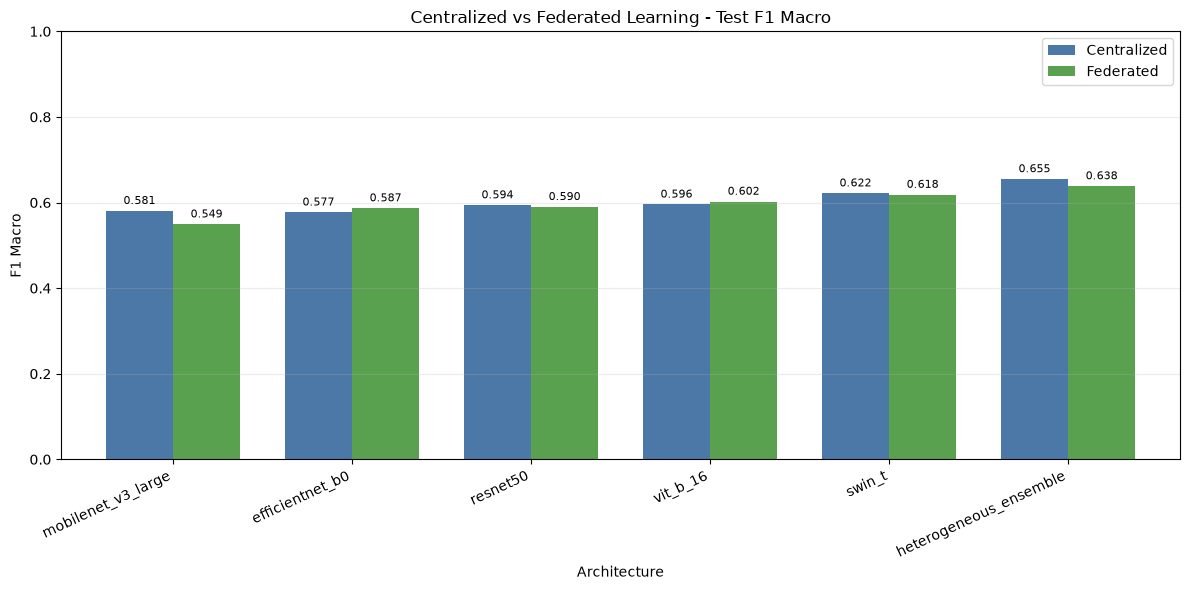

In [28]:
plot_data = df_comparison.set_index("model")

plot_data = plot_data.reindex([

    *ARCHITECTURES,

    "heterogeneous_ensemble"

])

ax = plot_data[[

    "centralized",

    "federated"

]].plot(

    kind="bar",

    figsize=(12, 6),

    width=0.75,

    color=["#4C78A8", "#59A14F"]

)

ax.set_title(

    "Centralized vs Federated Learning - Test F1 Macro"

)

ax.set_ylabel("F1 Macro")

ax.set_xlabel("Architecture")

ax.set_ylim(0, 1)

ax.legend([

    "Centralized",

    "Federated"

])

for container in ax.containers:

    ax.bar_label(

        container,

        fmt="%.3f",

        padding=3,

        fontsize=8

    )

plt.xticks(rotation=25, ha="right")

plt.grid(axis="y", alpha=0.25)

plt.tight_layout()

plt.savefig(

    ENSEMBLE_REPORTS_DIR

    / "centralized_vs_federated_f1.png",

    dpi=150

)

plt.show()

In [29]:
ensemble_improvements = []

for approach in [

    "centralized",

    "federated"

]:

    individual = df_individual[

        df_individual["approach"] == approach

    ]

    best_individual = individual.loc[

        individual["f1_macro"].idxmax()

    ]

    ensemble = df_ensembles[

        df_ensembles["approach"] == approach

    ].iloc[0]

    mean_individual = individual[

        "f1_macro"

    ].mean()

    ensemble_improvements.append({

        "approach": approach,

        "best_individual_model":

            best_individual["model"],

        "best_individual_f1":

            best_individual["f1_macro"],

        "mean_individual_f1":

            mean_individual,

        "ensemble_f1":

            ensemble["f1_macro"],

        "gain_vs_best_pp": (

            ensemble["f1_macro"]

            - best_individual["f1_macro"]

        ) * 100,

        "gain_vs_mean_pp": (

            ensemble["f1_macro"]

            - mean_individual

        ) * 100

    })

df_ensemble_improvements = pd.DataFrame(

    ensemble_improvements

)

display(

    df_ensemble_improvements.round(4)

)

df_ensemble_improvements.to_csv(

    ENSEMBLE_REPORTS_DIR

    / "ensemble_improvements.csv",

    index=False,

    encoding="utf-8-sig"

)

,approach,best_individual_model,best_individual_f1,mean_individual_f1,ensemble_f1,gain_vs_best_pp,gain_vs_mean_pp
0,centralized,swin_t,0.6216,0.5937,0.6549,3.3213,6.1115
1,federated,swin_t,0.6183,0.5893,0.6383,1.9966,4.9028


In [30]:
class_results = []

for approach in [

    "centralized",

    "federated"

]:

    for model_name in [

        *ARCHITECTURES,

        "heterogeneous_ensemble"

    ]:

        detailed = read_json(

            ENSEMBLE_REPORTS_DIR

            / approach

            / model_name

            / "detailed_metrics.json"

        )

        report = detailed["classification_report"]

        for class_name in CLASS_MAPPING:

            class_results.append({

                "approach": approach,

                "model": model_name,

                "class": class_name,

                "precision":

                    report[class_name]["precision"],

                "recall":

                    report[class_name]["recall"],

                "f1_score":

                    report[class_name]["f1-score"],

                "support":

                    report[class_name]["support"]

            })

df_class_results = pd.DataFrame(class_results)

assert len(df_class_results) == 60

df_class_results.to_csv(

    ENSEMBLE_REPORTS_DIR

    / "class_level_results.csv",

    index=False,

    encoding="utf-8-sig"

)

display(

    df_class_results[

        df_class_results["model"] == (

            "heterogeneous_ensemble"

        )

    ].round(4)

)

,approach,model,class,precision,recall,f1_score,support
25,centralized,heterogeneous_ensemble,bacterial_blight,0.4612,0.7301,0.5653,163.0
26,centralized,heterogeneous_ensemble,brown_streak_disease,0.5385,0.6402,0.5850,328.0
27,centralized,heterogeneous_ensemble,green_mottle,0.6030,0.6788,0.6386,358.0
28,centralized,heterogeneous_ensemble,healthy,0.5893,0.5969,0.5931,387.0
29,centralized,heterogeneous_ensemble,mosaic_disease,0.9445,0.8455,0.8923,1974.0
55,federated,heterogeneous_ensemble,bacterial_blight,0.4641,0.6748,0.5500,163.0
56,federated,heterogeneous_ensemble,brown_streak_disease,0.5219,0.6189,0.5662,328.0
57,federated,heterogeneous_ensemble,green_mottle,0.5766,0.6620,0.6164,358.0
58,federated,heterogeneous_ensemble,healthy,0.5457,0.6176,0.5794,387.0
59,federated,heterogeneous_ensemble,mosaic_disease,0.9401,0.8262,0.8795,1974.0


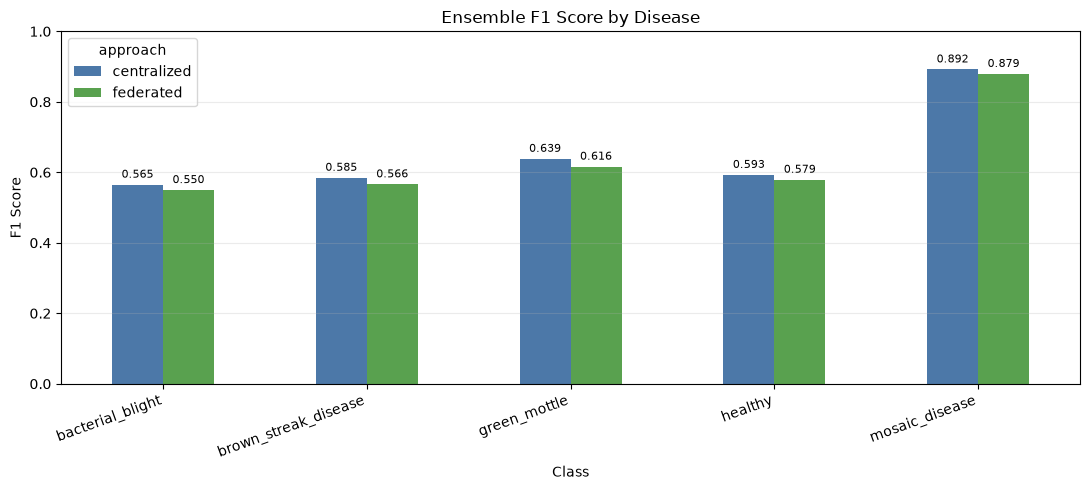

In [31]:
df_class_ensemble = df_class_results[

    df_class_results["model"] == (

        "heterogeneous_ensemble"

    )

].pivot(

    index="class",

    columns="approach",

    values="f1_score"

)

ax = df_class_ensemble.plot(

    kind="bar",

    figsize=(11, 5),

    color=["#4C78A8", "#59A14F"]

)

ax.set_title("Ensemble F1 Score by Disease")

ax.set_ylabel("F1 Score")

ax.set_xlabel("Class")

ax.set_ylim(0, 1)

for container in ax.containers:

    ax.bar_label(

        container,

        fmt="%.3f",

        padding=3,

        fontsize=8

    )

plt.xticks(rotation=20, ha="right")

plt.grid(axis="y", alpha=0.25)

plt.tight_layout()

plt.savefig(

    ENSEMBLE_REPORTS_DIR

    / "ensemble_class_comparison.png",

    dpi=150

)

plt.show()

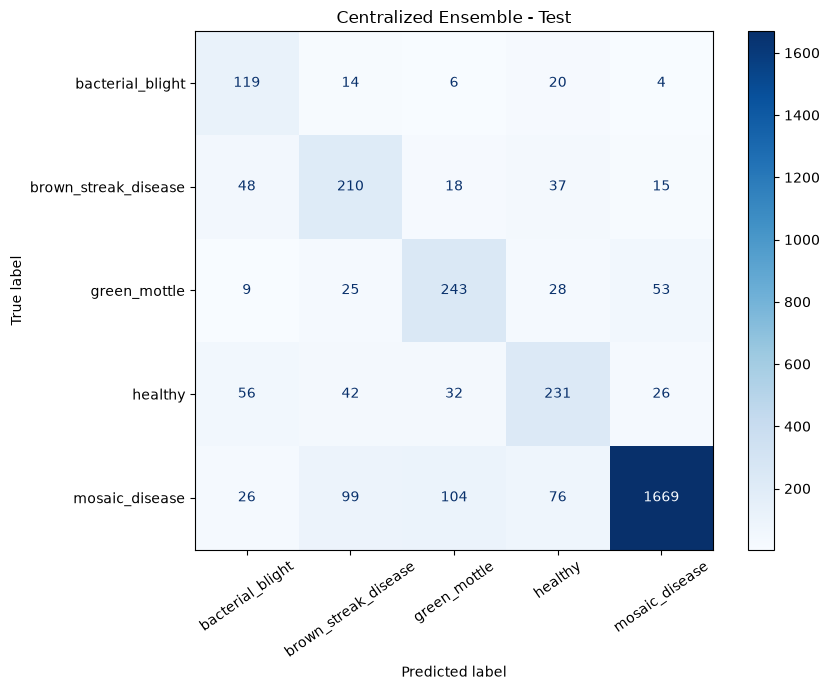

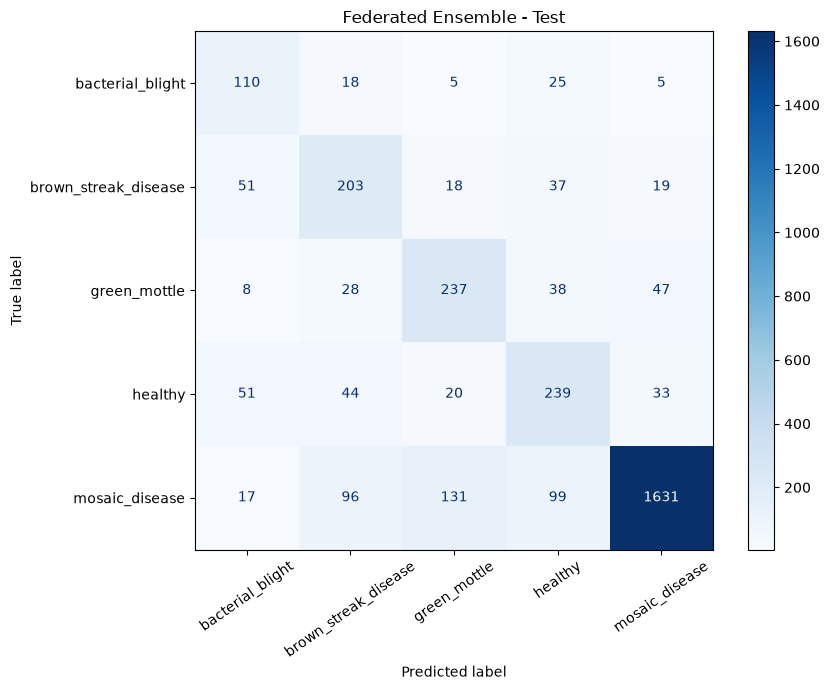

In [32]:
from sklearn.metrics import ConfusionMatrixDisplay

for approach in [

    "centralized",

    "federated"

]:

    detailed = read_json(

        ENSEMBLE_REPORTS_DIR

        / approach

        / "heterogeneous_ensemble"

        / "detailed_metrics.json"

    )

    matrix = np.asarray(

        detailed["confusion_matrix"]

    )

    assert matrix.sum() == len(df_test)

    fig, ax = plt.subplots(

        figsize=(9, 7)

    )

    display_matrix = ConfusionMatrixDisplay(

        confusion_matrix=matrix,

        display_labels=detailed["class_names"]

    )

    display_matrix.plot(

        ax=ax,

        cmap="Blues",

        values_format="d",

        xticks_rotation=35

    )

    ax.set_title(

        f"{approach.title()} Ensemble - Test"

    )

    plt.tight_layout()

    plt.savefig(

        ENSEMBLE_REPORTS_DIR

        / f"{approach}_ensemble_confusion.png",

        dpi=150

    )

    plt.show()

    plt.close(fig)

In [33]:
from itertools import combinations

disagreement_results = []

for approach in [

    "centralized",

    "federated"

]:

    predictions = {

        model_name:

            probabilities_by_approach[approach][

                model_name

            ].argmax(axis=1)

        for model_name in ARCHITECTURES

    }

    for model_a, model_b in combinations(

        ARCHITECTURES,

        2

    ):

        disagreement = np.mean(

            predictions[model_a]

            != predictions[model_b]

        )

        disagreement_results.append({

            "approach": approach,

            "model_a": model_a,

            "model_b": model_b,

            "disagreement": float(disagreement),

            "agreement": float(1 - disagreement)

        })

df_disagreement = pd.DataFrame(

    disagreement_results

)

assert len(df_disagreement) == 20

df_disagreement.to_csv(

    ENSEMBLE_REPORTS_DIR

    / "model_disagreement.csv",

    index=False,

    encoding="utf-8-sig"

)

display(df_disagreement.round(4))

,approach,model_a,model_b,disagreement,agreement
0,centralized,mobilenet_v3_large,efficientnet_b0,0.2498,0.7502
1,centralized,mobilenet_v3_large,resnet50,0.2458,0.7542
2,centralized,mobilenet_v3_large,vit_b_16,0.2729,0.7271
3,centralized,mobilenet_v3_large,swin_t,0.2480,0.7520
4,centralized,efficientnet_b0,resnet50,0.2505,0.7495
5,centralized,efficientnet_b0,vit_b_16,0.2741,0.7259
6,centralized,efficientnet_b0,swin_t,0.2467,0.7533
7,centralized,resnet50,vit_b_16,0.2738,0.7262
8,centralized,resnet50,swin_t,0.2436,0.7564
9,centralized,vit_b_16,swin_t,0.2533,0.7467


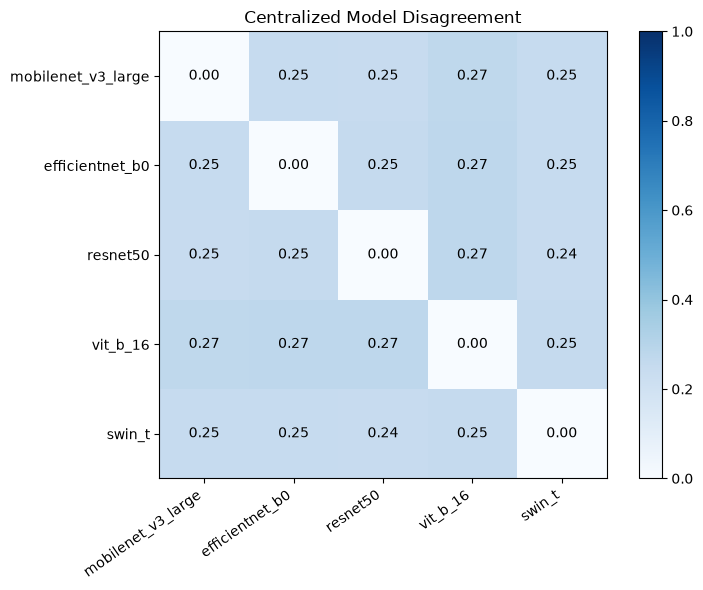

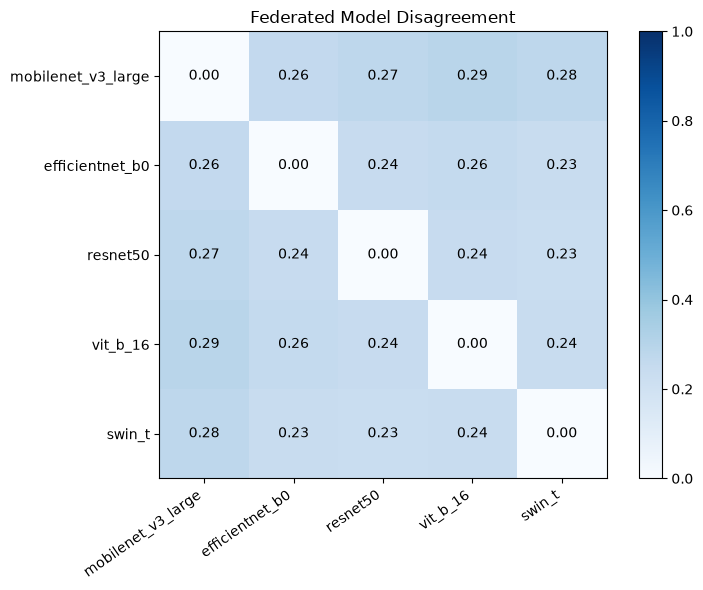

In [34]:
for approach in [

    "centralized",

    "federated"

]:

    matrix = pd.DataFrame(

        np.zeros((5, 5)),

        index=ARCHITECTURES,

        columns=ARCHITECTURES

    )

    rows = df_disagreement[

        df_disagreement["approach"] == approach

    ]

    for _, row in rows.iterrows():

        matrix.loc[

            row["model_a"],

            row["model_b"]

        ] = row["disagreement"]

        matrix.loc[

            row["model_b"],

            row["model_a"]

        ] = row["disagreement"]

    fig, ax = plt.subplots(figsize=(8, 6))

    image = ax.imshow(

        matrix.values,

        cmap="Blues",

        vmin=0,

        vmax=1

    )

    ax.set_xticks(range(5))

    ax.set_yticks(range(5))

    ax.set_xticklabels(

        ARCHITECTURES,

        rotation=35,

        ha="right"

    )

    ax.set_yticklabels(ARCHITECTURES)

    for i in range(5):

        for j in range(5):

            ax.text(

                j,

                i,

                f"{matrix.iloc[i, j]:.2f}",

                ha="center",

                va="center"

            )

    fig.colorbar(image, ax=ax)

    ax.set_title(

        f"{approach.title()} Model Disagreement"

    )

    plt.tight_layout()

    plt.savefig(

        ENSEMBLE_REPORTS_DIR

        / f"{approach}_disagreement.png",

        dpi=150

    )

    plt.show()

    plt.close(fig)

In [35]:
engine = CassavaInferenceEngine(

    project_dir=PROJECT_DIR,

    device=DEVICE

)

print("Inference device:", engine.device)

print("Architectures:", engine.architectures)

print("Classes:", engine.class_names)

Inference device: cuda
Architectures: ['mobilenet_v3_large', 'efficientnet_b0', 'resnet50', 'vit_b_16', 'swin_t']
Classes: ['bacterial_blight', 'brown_streak_disease', 'green_mottle', 'healthy', 'mosaic_disease']


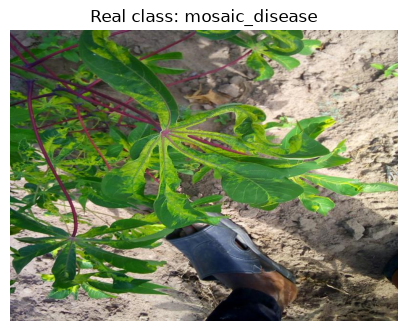

In [36]:
sample_row = df_development.sample(

    n=1,

    random_state=SEED

).iloc[0]

sample_path = (

    DATASET_DIR / sample_row["filepath"]

)

with Image.open(sample_path) as image:

    sample_image = image.copy()

plt.figure(figsize=(5, 5))

plt.imshow(sample_image)

plt.title(

    f"Real class: {sample_row['class']}"

)

plt.axis("off")

plt.show()

In [37]:
individual_prediction = engine.predict(

    image=sample_image,

    approach="both",

    model_name="mobilenet_v3_large"

)

display(individual_prediction)

{'model': 'mobilenet_v3_large',
 'approach': 'both',
 'results': {'centralized': {'predicted_index': 4,
   'predicted_class': 'mosaic_disease',
   'confidence': 0.9671638011932373,
   'probabilities': {'bacterial_blight': 0.005892426706850529,
    'brown_streak_disease': 0.012198062613606453,
    'green_mottle': 0.011508888565003872,
    'healthy': 0.0032368903048336506,
    'mosaic_disease': 0.9671638011932373},
   'individual_predictions': {'mobilenet_v3_large': {'predicted_index': 4,
     'predicted_class': 'mosaic_disease',
     'confidence': 0.9671638011932373,
     'probabilities': {'bacterial_blight': 0.005892426706850529,
      'brown_streak_disease': 0.012198062613606453,
      'green_mottle': 0.011508888565003872,
      'healthy': 0.0032368903048336506,
      'mosaic_disease': 0.9671638011932373}}}},
  'federated': {'predicted_index': 4,
   'predicted_class': 'mosaic_disease',
   'confidence': 0.9152842164039612,
   'probabilities': {'bacterial_blight': 0.026514628902077675,


In [38]:
ensemble_prediction = engine.predict(

    image=sample_image,

    approach="both",

    model_name="ensemble"

)

for approach, result in (

    ensemble_prediction["results"].items()

):

    print("\nApproach:", approach)

    print(

        "Predicted class:",

        result["predicted_class"]

    )

    print(

        "Confidence:",

        round(result["confidence"] * 100, 2),

        "%"

    )

    display(

        pd.DataFrame([

            {

                "class": class_name,

                "probability": probability

            }

            for class_name, probability

            in result["probabilities"].items()

        ]).sort_values(

            "probability",

            ascending=False

        )

    )

print(

    "End-to-end inference seconds:",

    round(

        ensemble_prediction["inference_seconds"],

        4

    )

)


Approach: centralized
Predicted class: mosaic_disease
Confidence: 89.54 %


,class,probability
4,mosaic_disease,0.895432
2,green_mottle,0.033090
0,bacterial_blight,0.029487
1,brown_streak_disease,0.021926
3,healthy,0.020065



Approach: federated
Predicted class: mosaic_disease
Confidence: 88.72 %


,class,probability
4,mosaic_disease,0.887237
2,green_mottle,0.038496
1,brown_streak_disease,0.027449
0,bacterial_blight,0.024596
3,healthy,0.022221


End-to-end inference seconds: 7.3322


In [39]:
engine.unload()

sample_index = int(sample_row.name)

integration_verification = []

for model_name in ARCHITECTURES:

    cache = torch.load(

        development_cache_dir

        / f"{model_name}.pth",

        map_location="cpu",

        weights_only=True

    )

    assert cache["filepaths"][sample_index] == (

        sample_row["filepath"]

    )

    bundle = engine.get_bundle(model_name)

    direct_features = extract_batch_features(

        extractor=bundle["extractor"],

        images=engine.preprocess(sample_image),

        device=DEVICE,

        mixed_precision=

            mixed_precision_by_model[model_name]

    )

    cached_features = cache["features"][

        sample_index:sample_index + 1

    ]

    for approach in [

        "centralized",

        "federated"

    ]:

        direct_probs = (

            predict_cached_probabilities(

                classifier=bundle[approach],

                features=direct_features,

                device=DEVICE

            )

        )

        cached_probs = (

            predict_cached_probabilities(

                classifier=bundle[approach],

                features=cached_features,

                device=DEVICE

            )

        )

        max_difference = float(

            np.abs(

                direct_probs - cached_probs

            ).max()

        )

        integration_verification.append({

            "architecture": model_name,

            "approach": approach,

            "max_probability_difference":

                max_difference,

            "prediction_agreement": bool(

                direct_probs.argmax()

                == cached_probs.argmax()

            ),

            "probabilities_close": bool(

                np.allclose(

                    direct_probs,

                    cached_probs,

                    atol=0.01,

                    rtol=0.01

                )

            )

        })

    del bundle
    del cache
    del direct_features
    del cached_features

    engine.unload()

df_integration_verification = pd.DataFrame(

    integration_verification

)

display(

    df_integration_verification.round(6)

)

assert len(df_integration_verification) == 10

assert (

    df_integration_verification[

        "probabilities_close"

    ]

).all()

df_integration_verification.to_csv(

    ENSEMBLE_REPORTS_DIR

    / "inference_integration_verification.csv",

    index=False,

    encoding="utf-8-sig"

)

,architecture,approach,max_probability_difference,prediction_agreement,probabilities_close
0,mobilenet_v3_large,centralized,0.000033,True,True
1,mobilenet_v3_large,federated,0.000093,True,True
2,efficientnet_b0,centralized,0.000171,True,True
3,efficientnet_b0,federated,0.000101,True,True
4,resnet50,centralized,0.000063,True,True
5,resnet50,federated,0.000081,True,True
6,vit_b_16,centralized,0.000594,True,True
7,vit_b_16,federated,0.000333,True,True
8,swin_t,centralized,0.000024,True,True
9,swin_t,federated,0.000028,True,True


In [40]:
for approach, result in (

    ensemble_prediction["results"].items()

):

    probabilities = np.array(

        [

            result["probabilities"][class_name]

            for class_name in engine.class_names

        ]

    )

    assert len(probabilities) == NUM_CLASSES

    assert np.isfinite(probabilities).all()

    assert np.isclose(

        probabilities.sum(),

        1.0,

        atol=1e-5

    )

    individual_probabilities = {}

    for model_name, prediction in (

        result["individual_predictions"].items()

    ):

        individual_probabilities[model_name] = (

            np.array([

                [

                    prediction["probabilities"][c]

                    for c in engine.class_names

                ]

            ])

        )

    expected = soft_voting(

        individual_probabilities,

        weights=ensemble_config["weights"]

    )[0]

    assert np.allclose(

        probabilities,

        expected,

        atol=1e-6

    )

    assert result["predicted_index"] == (

        probabilities.argmax()

    )

    print(approach, "| Integration: OK")

save_json(

    ensemble_prediction,

    ENSEMBLE_REPORTS_DIR

    / "inference_example.json"

)

engine.unload()

centralized | Integration: OK
federated | Integration: OK


In [41]:
df_extraction = pd.read_csv(

    ENSEMBLE_REPORTS_DIR

    / "test_feature_extraction.csv"

)

assert len(df_extraction) == 5

assert (

    df_extraction["shared_backbone_verified"]

).all()

df_extraction["extraction_minutes"] = (

    df_extraction["extraction_seconds"] / 60

)

df_extraction["images_per_second"] = (

    df_extraction["images"]

    / df_extraction["extraction_seconds"]

)

display(

    df_extraction.round(4)

)

total_extraction_seconds = (

    df_extraction["extraction_seconds"].sum()

)

total_classifier_seconds = (

    df_individual["inference_seconds"].sum()

)

total_voting_seconds = (

    df_ensembles["inference_seconds"].sum()

)

compute_summary = {

    "feature_extraction_seconds":

        float(total_extraction_seconds),

    "classifier_inference_seconds":

        float(total_classifier_seconds),

    "soft_voting_seconds":

        float(total_voting_seconds),

    "cache_size_mib":

        float(df_extraction["cache_size_mib"].sum()),

    "actual_image_backbone_passes":

        len(df_test) * len(ARCHITECTURES),

    "separate_model_image_backbone_passes":

        len(df_test) * len(ARCHITECTURES) * 2,

    "backbone_pass_reduction_pct": 50.0,

    "example_end_to_end_inference_seconds":

        ensemble_prediction["inference_seconds"]

}

save_json(

    compute_summary,

    ENSEMBLE_REPORTS_DIR

    / "computational_summary.json"

)

display(compute_summary)

,architecture,images,feature_dim,extraction_seconds,cache_size_mib,shared_backbone_verified,execution_seconds,extraction_minutes,images_per_second
0,mobilenet_v3_large,3210,960,39.2115,11.8990,True,40.3165,0.6535,81.8638
1,efficientnet_b0,3210,1280,37.6803,15.8175,True,38.4840,0.6280,85.1905
2,resnet50,3210,2048,46.7973,25.2216,True,48.5335,0.7800,68.5937
3,vit_b_16,3210,768,83.9592,9.5478,True,87.0333,1.3993,38.2329
4,swin_t,3210,768,49.3477,9.5477,True,51.2105,0.8225,65.0486


{'feature_extraction_seconds': 256.9959983999979,
 'classifier_inference_seconds': 0.30262510000829934,
 'soft_voting_seconds': 0.003342500000144355,
 'cache_size_mib': 72.03367614746094,
 'actual_image_backbone_passes': 16050,
 'separate_model_image_backbone_passes': 32100,
 'backbone_pass_reduction_pct': 50.0,
 'example_end_to_end_inference_seconds': 7.332208499999979}

In [42]:
ensemble_registry = {

    "run_id": RUN_ID,

    "num_ensembles": 2,

    "num_models_per_ensemble": 5,

    "num_classes": NUM_CLASSES,

    "class_mapping": CLASS_MAPPING,

    "method": "soft_voting",

    "weights": ensemble_config["weights"],

    "architectures": ARCHITECTURES,

    "shared_backbones": True,

    "inference_module": "src/inference.py",

    "inference_config": "configs/inference_config.json",

    "ensembles": {

        "centralized": {

            "registry":

                "configs/centralized_model_registry.json",

            "metrics_path": str(

                (

                    ENSEMBLE_REPORTS_DIR

                    / "centralized"

                    / "heterogeneous_ensemble"

                    / "metrics.json"

                ).relative_to(PROJECT_DIR)

            )

        },

        "federated": {

            "registry":

                "configs/federated_model_registry.json",

            "metrics_path": str(

                (

                    ENSEMBLE_REPORTS_DIR

                    / "federated"

                    / "heterogeneous_ensemble"

                    / "metrics.json"

                ).relative_to(PROJECT_DIR)

            )

        }

    },

    "evaluation_split": "test",

    "test_images": len(df_test),

    "test_evaluation_completed": True,

    "test_used_for_weight_optimization": False

}

save_json(

    ensemble_registry,

    CONFIGS_DIR / "ensemble_model_registry.json"

)

display(ensemble_registry)

{'run_id': 'ensemble_cached_v1',
 'num_ensembles': 2,
 'num_models_per_ensemble': 5,
 'num_classes': 5,
 'class_mapping': {'bacterial_blight': 0,
  'brown_streak_disease': 1,
  'green_mottle': 2,
  'healthy': 3,
  'mosaic_disease': 4},
 'method': 'soft_voting',
 'weights': {'mobilenet_v3_large': 0.2,
  'efficientnet_b0': 0.2,
  'resnet50': 0.2,
  'vit_b_16': 0.2,
  'swin_t': 0.2},
 'architectures': ['mobilenet_v3_large',
  'efficientnet_b0',
  'resnet50',
  'vit_b_16',
  'swin_t'],
 'shared_backbones': True,
 'inference_module': 'src/inference.py',
 'inference_config': 'configs/inference_config.json',
 'ensembles': {'centralized': {'registry': 'configs/centralized_model_registry.json',
   'metrics_path': 'reports\\ensemble\\ensemble_cached_v1\\centralized\\heterogeneous_ensemble\\metrics.json'},
  'federated': {'registry': 'configs/federated_model_registry.json',
   'metrics_path': 'reports\\ensemble\\ensemble_cached_v1\\federated\\heterogeneous_ensemble\\metrics.json'}},
 'evaluation_

In [43]:
assert len(df_individual) == 10

assert len(df_ensembles) == 2

assert len(df_all_results) == 12

assert len(df_extraction) == 5

assert len(df_class_results) == 60

assert len(df_integration_verification) == 10

assert (

    df_integration_verification[

        "probabilities_close"

    ]

).all()

assert (

    df_all_results["num_samples"] == 3210

).all()

assert not df_all_results.duplicated(

    subset=["model", "approach"]

).any()

assert np.isclose(

    sum(ensemble_config["weights"].values()),

    1.0

)

assert not ensemble_config[

    "optimize_ensemble_weights"

]

assert len(ensemble_registry["ensembles"]) == 2

assert len(inference_config["available_models"]) == 6

assert (

    df_all_results["f1_macro"]

    .between(0, 1)

).all()

print(

    "Evaluación, ensembles e integración "

    "verificados correctamente."

)

Evaluación, ensembles e integración verificados correctamente.


In [44]:
ensemble_summary = {

    "phase": "phase_4",

    "experiment": "ensemble_and_integration",

    "run_id": RUN_ID,

    "status": "completed",

    "method": "soft_voting",

    "weighting": "uniform",

    "architectures": 5,

    "cnn_architectures": 3,

    "transformer_architectures": 2,

    "centralized_models_evaluated": 5,

    "federated_models_evaluated": 5,

    "centralized_ensembles": 1,

    "federated_ensembles": 1,

    "total_evaluated_systems": 12,

    "test_images": len(df_test),

    "primary_metric": "f1_macro",

    "centralized_ensemble_f1": float(

        centralized_ensemble_result["f1_macro"]

    ),

    "federated_ensemble_f1": float(

        federated_ensemble_result["f1_macro"]

    ),

    "centralized_ensemble_accuracy": float(

        centralized_ensemble_result["accuracy"]

    ),

    "federated_ensemble_accuracy": float(

        federated_ensemble_result["accuracy"]

    ),

    "shared_backbones_verified": 5,

    "test_feature_caches": 5,

    "integration_checks": 10,

    "integration_checks_passed": int(

        df_integration_verification[

            "probabilities_close"

        ].sum()

    ),

    "feature_caching": True,

    "new_training_performed": False,

    "ensemble_weights_optimized": False,

    "test_used": True,

    "test_used_for_training": False,

    "test_used_for_model_selection": False,

    "inference_engine_ready": True,

    "ensemble_registry_generated": True,

    "product_interface_pending": True,

    "compute_summary": compute_summary,

    "timestamp": datetime.now().isoformat()

}

save_json(

    ensemble_summary,

    ENSEMBLE_EXPERIMENTS_DIR

    / "ensemble_summary.json"

)

display(ensemble_summary)

print("=" * 65)

print(

    "FASE 4 - ENSEMBLE E INTEGRACIÓN COMPLETADA"

)

print("=" * 65)

engine.unload()

release_memory()

{'phase': 'phase_4',
 'experiment': 'ensemble_and_integration',
 'run_id': 'ensemble_cached_v1',
 'status': 'completed',
 'method': 'soft_voting',
 'weighting': 'uniform',
 'architectures': 5,
 'cnn_architectures': 3,
 'transformer_architectures': 2,
 'centralized_models_evaluated': 5,
 'federated_models_evaluated': 5,
 'centralized_ensembles': 1,
 'federated_ensembles': 1,
 'total_evaluated_systems': 12,
 'test_images': 3210,
 'primary_metric': 'f1_macro',
 'centralized_ensemble_f1': 0.6548510176536672,
 'federated_ensemble_f1': 0.638301890349369,
 'centralized_ensemble_accuracy': 0.7700934579439253,
 'federated_ensemble_accuracy': 0.7538940809968847,
 'shared_backbones_verified': 5,
 'test_feature_caches': 5,
 'integration_checks': 10,
 'integration_checks_passed': 10,
 'feature_caching': True,
 'new_training_performed': False,
 'ensemble_weights_optimized': False,
 'test_used': True,
 'test_used_for_training': False,
 'test_used_for_model_selection': False,
 'inference_engine_ready'

FASE 4 - ENSEMBLE E INTEGRACIÓN COMPLETADA
